# Posterior for ClonalOrigin simulation local recombination rate and mutation rate using SBI

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from Bio import Phylo
import seaborn as sns
import torch
from torch.distributions import Uniform
import sbi
from sbi.utils.user_input_checks import MultipleIndependent
from sbi.neural_nets import posterior_nn
from sbi.inference import NPE_C
from sbi.analysis import plot_summary
from sbi.diagnostics import run_sbc, check_sbc, run_tarp, check_tarp
from sbi.analysis import sbc_rank_plot
from sbi.analysis import plot_tarp
import warnings
import sys
sys.path.append('../pysimARG')
from discrete_uniform import DiscreteUniform
from LeaveLengthOut_NN import LeaveLengthOut_NN

torch_device = "cpu"
warnings.filterwarnings("ignore", category=UserWarning)

c:\Users\u2008181\likelihood-free\sbi_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load simulation data

In [2]:
drop_col = range(16, 32)

In [3]:
x_500 = np.loadtxt("../data/ClonalOrigin/x_o_500.csv", delimiter=",")
x_500 = np.delete(x_500, drop_col, axis=1)
x_2000 = np.loadtxt("../data/ClonalOrigin/x_o_2000.csv", delimiter=",")
x_2000 = np.delete(x_2000, drop_col, axis=1)
x_6000 = np.loadtxt("../data/ClonalOrigin/x_o_6000.csv", delimiter=",")
x_6000 = np.delete(x_6000, drop_col, axis=1)

x_500.shape, x_2000.shape, x_6000.shape

((100, 30), (100, 30), (100, 30))

In [4]:
theta1 = np.loadtxt('../data/ClonalOrigin/rho_and_theta/theta1.csv', delimiter=",")
x1 = np.loadtxt('../data/ClonalOrigin/rho_and_theta/x1.csv', delimiter=",")

theta2 = np.loadtxt('../data/ClonalOrigin/rho_and_theta/theta2.csv', delimiter=",")
x2 = np.loadtxt('../data/ClonalOrigin/rho_and_theta/x2.csv', delimiter=",")

theta3 = np.loadtxt('../data/ClonalOrigin/rho_and_theta/theta3.csv', delimiter=",")
x3 = np.loadtxt('../data/ClonalOrigin/rho_and_theta/x3.csv', delimiter=",")

theta4 = np.loadtxt('../data/ClonalOrigin/rho_and_theta/theta4.csv', delimiter=",")
x4 = np.loadtxt('../data/ClonalOrigin/rho_and_theta/x4.csv', delimiter=",")

x = np.vstack([x1, x2, x3, x4])
x = np.delete(x, drop_col, axis=1)
theta = np.vstack([theta1, theta2, theta3, theta4])

print(theta.shape, x.shape)

(50000, 3) (50000, 30)


In [5]:
drop_indices = np.unique(np.concatenate([np.where(np.isnan(x))[0], np.where(np.isinf(x))[0]]))
theta = np.delete(theta, drop_indices, axis=0)
x = np.delete(x, drop_indices, axis=0)

theta = torch.tensor(theta, device=torch_device)
theta = theta.to(torch.float32)
theta_numpy = theta.cpu().numpy()

x = torch.tensor(x, device=torch_device)
x = x.to(torch.float32)
x_numpy = x.cpu().numpy()

print(theta.shape, x.shape)

torch.Size([49948, 3]) torch.Size([49948, 30])


## NPE

### Create prior to pass range knowledge to NPE

In [6]:
prior_rho = Uniform(low=torch.tensor([0.0]), high=torch.tensor([0.1]))
prior_theta = Uniform(low=torch.tensor([0.0]), high=torch.tensor([0.1]))
prior_L = DiscreteUniform(low=torch.tensor([100.0]), high=torch.tensor([10000.0]))

prior = MultipleIndependent(
    dists=[prior_rho, prior_theta, prior_L],
    validate_args=False,
    device=torch_device
)

### Using all simulations

In [7]:
embedding_net = LeaveLengthOut_NN(
    input_dim=30,
    num_hiddens=128,
    num_hidden_layers=1,
    num_outputs=2)
neural_posterior = posterior_nn(
    model="nsf",
    embedding_net=embedding_net,
    hidden_features=30,
    num_transforms=8,
    num_bins=5,
    z_score_theta="independent",
    z_score_x="independent"
)

In [8]:
seed = 100
num_posterior_samples=1000

inference = NPE_C(density_estimator=neural_posterior, device=torch_device)
torch.manual_seed(seed)
np.random.seed(seed)

In [9]:
# density_estimator = inference.append_simulations(theta, x).train(
#     max_num_epochs=500,
#     training_batch_size=100,
#     learning_rate=0.0001,
#     stop_after_epochs=20,
#     clip_max_norm=None
# )
# posterior = inference.build_posterior(density_estimator)

In [10]:
# fig, axes = plot_summary(
#     inference, 
#     tags=["training_loss", "validation_loss"], 
#     figsize=(8, 4)
# )
# plt.title("Training and Validation Loss")
# plt.show()

### Save the trained NPE

In [11]:
save_path = "../data/ClonalOrigin/trained_npe_posterior_100.pt"

# torch.save(
#     {
#         "posterior": posterior,
#         "sbi_version": sbi.__version__,
#         "seed": seed,
#         "learning_rate": 0.0001,
#         "max_num_epochs": 500,
#     },
#     save_path,
# )

In [12]:
checkpoint = torch.load(save_path, map_location="cpu")
posterior = checkpoint["posterior"]

C:\Users\u2008181\AppData\Local\Temp\ipykernel_18552\1569981112.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(save_path, map_location="cpu")


#### ClonalOrigin observations

In [13]:
theta1_500 = np.full((100, num_posterior_samples, 3), np.nan)
theta1_2000 = np.full((100, num_posterior_samples, 3), np.nan)
theta1_6000 = np.full((100, num_posterior_samples, 3), np.nan)

theta1_500.shape, theta1_2000.shape, theta1_6000.shape

((100, 1000, 3), (100, 1000, 3), (100, 1000, 3))

In [14]:
for i in range(100):
    x_obs = torch.tensor(x_500[i, :], device=torch_device)
    x_obs = x_obs.to(torch.float32)
    theta_post = posterior.sample((num_posterior_samples,), x=x_obs, show_progress_bars=False)
    theta1_500[i, :, :] = theta_post.cpu().numpy()

In [15]:
for i in range(100):
    x_obs = torch.tensor(x_2000[i, :], device=torch_device)
    x_obs = x_obs.to(torch.float32)
    theta_post = posterior.sample((num_posterior_samples,), x=x_obs, show_progress_bars=False)
    theta1_2000[i, :, :] = theta_post.cpu().numpy()

In [16]:
for i in range(100):
    x_obs = torch.tensor(x_6000[i, :], device=torch_device)
    x_obs = x_obs.to(torch.float32)
    theta_post = posterior.sample((num_posterior_samples,), x=x_obs, show_progress_bars=False)
    theta1_6000[i, :, :] = theta_post.cpu().numpy()

<Figure size 800x800 with 0 Axes>

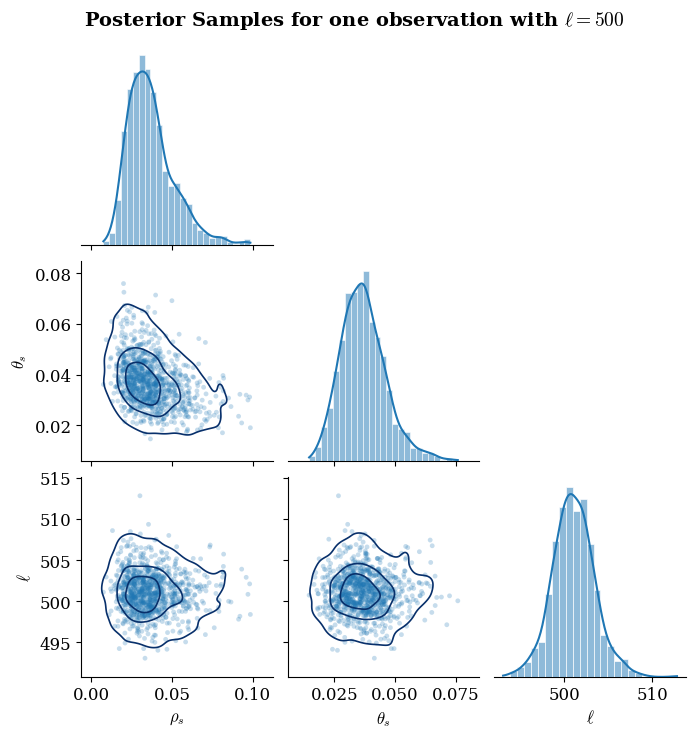

In [63]:
df_500 = pd.DataFrame(theta1_500[10, :, :], columns=[r"$\rho_s$", r"$\theta_s$", r"$\ell$"])

plt.figure(figsize=(8, 8))
g = sns.PairGrid(df_500, corner=True, height=2.4, aspect=1.0, diag_sharey=False)

g.map_lower(
    sns.scatterplot, 
    s=12, alpha=0.25, color="#1f77b4", edgecolor="none"
)
g.map_lower(
    sns.kdeplot, 
    levels=4, color="#08306b", linewidths=1.2
)

g.map_diag(
    sns.histplot, 
    kde=True, stat="density", color="#1f77b4", 
    edgecolor="white", alpha=0.5, bins=25,
    line_kws={"linewidth": 1.5, "color": "#08306b"}
)

g.fig.subplots_adjust(wspace=0.08, hspace=0.08)

g.fig.suptitle(
    r"Posterior Samples for one observation with $\ell = 500$", 
    fontsize=14, fontweight="bold", y=1.02
)

plt.savefig("../output/sim_500.pdf", bbox_inches="tight")
plt.show()

<Figure size 800x800 with 0 Axes>

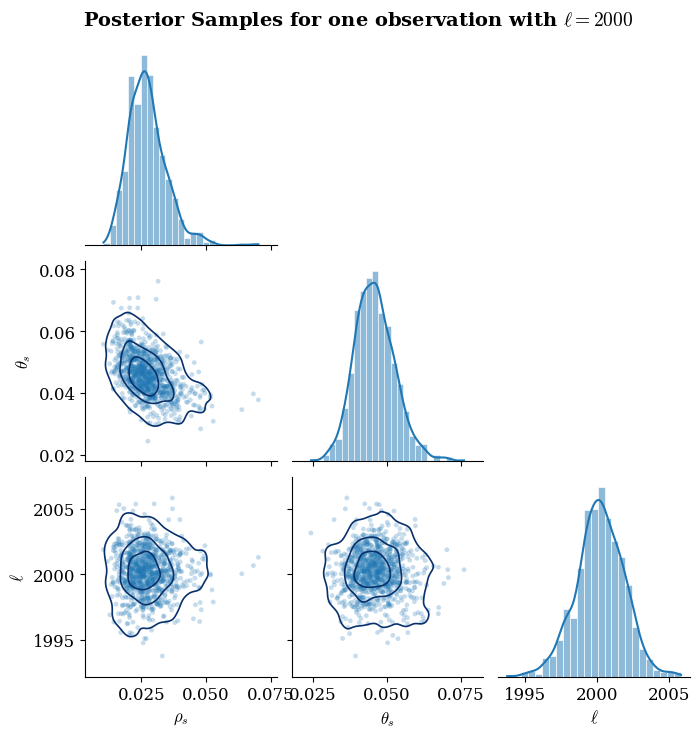

In [64]:
df_2000 = pd.DataFrame(theta1_2000[11, :, :], columns=[r"$\rho_s$", r"$\theta_s$", r"$\ell$"])

plt.figure(figsize=(8, 8))
g = sns.PairGrid(df_2000, corner=True, height=2.4, aspect=1.0, diag_sharey=False)

g.map_lower(
    sns.scatterplot, 
    s=12, alpha=0.25, color="#1f77b4", edgecolor="none"
)
g.map_lower(
    sns.kdeplot, 
    levels=4, color="#08306b", linewidths=1.2
)

g.map_diag(
    sns.histplot, 
    kde=True, stat="density", color="#1f77b4", 
    edgecolor="white", alpha=0.5, bins=25,
    line_kws={"linewidth": 1.5, "color": "#08306b"}
)

g.fig.subplots_adjust(wspace=0.08, hspace=0.08)

g.fig.suptitle(
    r"Posterior Samples for one observation with $\ell = 2000$", 
    fontsize=14, fontweight="bold", y=1.02
)

plt.savefig("../output/sim_2000.pdf", bbox_inches="tight")
plt.show()

<Figure size 800x800 with 0 Axes>

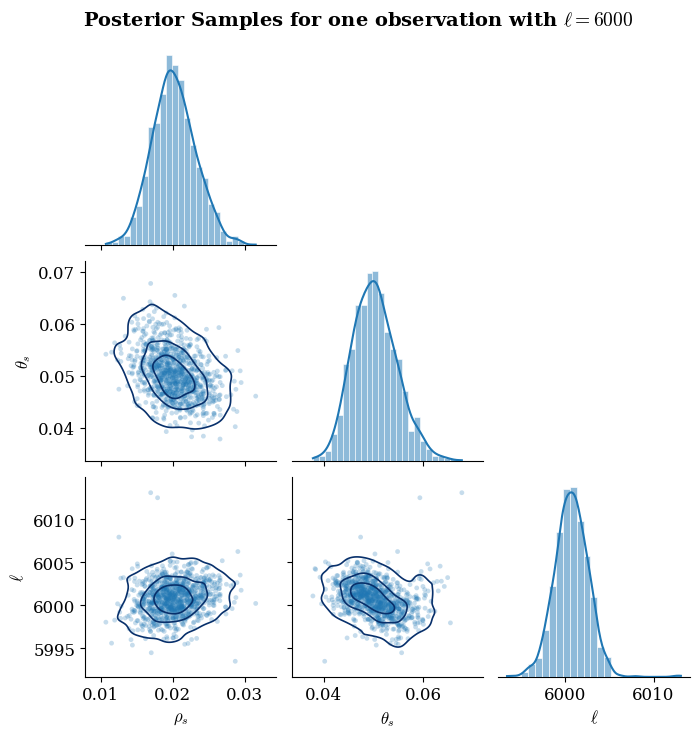

In [65]:
df_6000 = pd.DataFrame(theta1_6000[12, :, :], columns=[r"$\rho_s$", r"$\theta_s$", r"$\ell$"])

plt.figure(figsize=(8, 8))
g = sns.PairGrid(df_6000, corner=True, height=2.4, aspect=1.0, diag_sharey=False)

g.map_lower(
    sns.scatterplot, 
    s=12, alpha=0.25, color="#1f77b4", edgecolor="none"
)
g.map_lower(
    sns.kdeplot, 
    levels=4, color="#08306b", linewidths=1.2
)

g.map_diag(
    sns.histplot, 
    kde=True, stat="density", color="#1f77b4", 
    edgecolor="white", alpha=0.5, bins=25,
    line_kws={"linewidth": 1.5, "color": "#08306b"}
)

g.fig.subplots_adjust(wspace=0.08, hspace=0.08)

g.fig.suptitle(
    r"Posterior Samples for one observation with $\ell = 6000$", 
    fontsize=14, fontweight="bold", y=1.02
)

plt.savefig("../output/sim_6000.pdf", bbox_inches="tight")
plt.show()

## Test estimated posterior

In [66]:
theta_test = np.loadtxt('../data/ClonalOrigin/rho_and_theta/theta_sbc.csv', delimiter=",")
x_test = np.loadtxt('../data/ClonalOrigin/rho_and_theta/x_sbc.csv', delimiter=",")

theta_test = torch.tensor(theta_test, device=torch_device)
theta_test = theta_test.to(torch.float32)
theta_numpy = theta_test.cpu().numpy()

x_test = np.delete(x_test, drop_col, axis=1)
x_test = torch.tensor(x_test, device=torch_device)
x_test = x_test.to(torch.float32)
x_test_numpy = x_test.cpu().numpy()

print(theta_test.shape, x_test.shape)

torch.Size([1000, 3]) torch.Size([1000, 30])


In [67]:
nan_row = np.where(np.isnan(x_test_numpy))[0]
nan_row

array([865, 899])

In [68]:
theta_test = theta_test[~np.isnan(x_test_numpy).any(axis=1)]
x_test = x_test[~np.isnan(x_test_numpy).any(axis=1)]
theta_test.shape, x_test.shape

(torch.Size([998, 3]), torch.Size([998, 30]))

In [69]:
theta_numpy = theta_test.cpu().numpy()
x_test_numpy = x_test.cpu().numpy()

In [70]:
theta_test_post = np.full((theta_test.shape[0], num_posterior_samples, 3), np.nan)
for i in range(theta_test.shape[0]):
    theta_post = posterior.sample((num_posterior_samples,), x=x_test[i, :],
                                   show_progress_bars=False, reject_outside_prior=False)
    theta_test_post[i, :, :] = theta_post.detach().cpu().numpy()

theta_test_post.shape

(998, 1000, 3)

In [71]:
post_mid_rho = np.median(theta_test_post[:, :, 0], axis=1)
post_mid_theta = np.median(theta_test_post[:, :, 1], axis=1)
post_mid_L = np.median(theta_test_post[:, :, 2], axis=1)
post_mid_rho.shape, post_mid_theta.shape, post_mid_L.shape

((998,), (998,), (998,))

In [72]:
rho_lower_bounds = np.percentile(theta_test_post[:, :, 0], 2.5, axis=1)
rho_upper_bounds = np.percentile(theta_test_post[:, :, 0], 97.5, axis=1)

theta_lower_bounds = np.percentile(theta_test_post[:, :, 1], 2.5, axis=1)
theta_upper_bounds = np.percentile(theta_test_post[:, :, 1], 97.5, axis=1)

l_lower_bounds = np.percentile(theta_test_post[:, :, 2], 2.5, axis=1)
l_upper_bounds = np.percentile(theta_test_post[:, :, 2], 97.5, axis=1)

rho_lower_bounds.shape, rho_upper_bounds.shape, theta_lower_bounds.shape, theta_upper_bounds.shape, l_lower_bounds.shape, l_upper_bounds.shape

((998,), (998,), (998,), (998,), (998,), (998,))

In [73]:
rho_lower_errors = post_mid_rho - rho_lower_bounds
rho_upper_errors = rho_upper_bounds - post_mid_rho
yerr_rho = [rho_lower_errors, rho_upper_errors]

theta_lower_errors = post_mid_theta - theta_lower_bounds
theta_upper_errors = theta_upper_bounds - post_mid_theta
yerr_theta = [theta_lower_errors, theta_upper_errors]

l_lower_errors = post_mid_L - l_lower_bounds
l_upper_errors = l_upper_bounds - post_mid_L
yerr_L = [l_lower_errors, l_upper_errors]

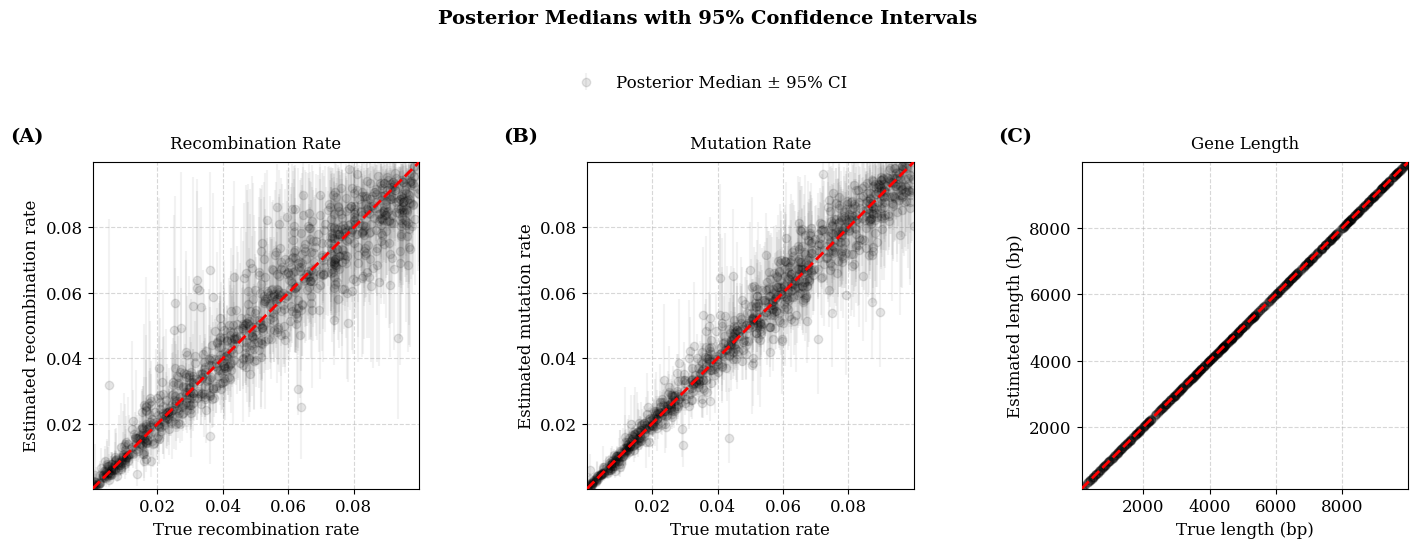

In [74]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=False)
fig.suptitle('Posterior Medians with 95% Confidence Intervals', fontsize=14, fontweight='bold', y=1.05)

# Dim 1
exact_x = np.linspace(torch.min(theta_test[:, 0]), torch.max(theta_test[:, 0]), 400)
exact_y = exact_x
axes[0].plot(exact_x, exact_y, color='red', linestyle='dashed', zorder=3, linewidth=2)
axes[0].errorbar(theta_test[:, 0], post_mid_rho, yerr=yerr_rho, fmt='o', color='black', 
             ecolor='gray', capsize=0, elinewidth=1.5, markersize=6, alpha=0.1,
             label='Posterior Median ± 95% CI')
axes[0].set_xlabel("True recombination rate", fontsize=12)
axes[0].set_ylabel("Estimated recombination rate", fontsize=12)
axes[0].set_title("Recombination Rate", fontsize=12, pad=10)
axes[0].grid(True, linestyle='--', alpha=0.5)
min_val = min(exact_x)
max_val = max(exact_x)
axes[0].set_xlim(min_val, max_val)
axes[0].set_ylim(min_val, max_val)
axes[0].set_aspect('equal', adjustable='box')

# Dim 2
exact_x = np.linspace(torch.min(theta_test[:, 1]), torch.max(theta_test[:, 1]), 400)
exact_y = exact_x
axes[1].plot(exact_x, exact_y, color='red', linestyle='dashed', zorder=3, linewidth=2)
axes[1].errorbar(theta_test[:, 1], post_mid_theta, yerr=yerr_theta, fmt='o', color='black', 
             ecolor='gray', capsize=0, elinewidth=1.5, markersize=6, alpha=0.1,
             label='Posterior Median ± 95% CI')
axes[1].set_xlabel("True mutation rate", fontsize=12)
axes[1].set_ylabel("Estimated mutation rate", fontsize=12)
axes[1].set_title("Mutation Rate", fontsize=12, pad=10)
axes[1].grid(True, linestyle='--', alpha=0.5)
min_val = min(exact_x)
max_val = max(exact_x)
axes[1].set_xlim(min_val, max_val)
axes[1].set_ylim(min_val, max_val)
axes[1].set_aspect('equal', adjustable='box')

# Dim 3
exact_x = np.linspace(torch.min(theta_test[:, 2]), torch.max(theta_test[:, 2]), 400)
exact_y = exact_x
axes[2].plot(exact_x, exact_y, color='red', linestyle='dashed', zorder=3, linewidth=2)
axes[2].errorbar(theta_test[:, 2], post_mid_L, yerr=yerr_L, fmt='o', color='black', 
             ecolor='gray', capsize=0, elinewidth=1.5, markersize=6, alpha=0.1,
             label='Posterior Median ± 95% CI')
axes[2].set_xlabel("True length (bp)", fontsize=12)
axes[2].set_ylabel("Estimated length (bp)", fontsize=12)
axes[2].set_title("Gene Length", fontsize=12, pad=10)
axes[2].grid(True, linestyle='--', alpha=0.5)
min_val = min(exact_x)
max_val = max(exact_x)
axes[2].set_xlim(min_val, max_val)
axes[2].set_ylim(min_val, max_val)
axes[2].set_aspect('equal', adjustable='box')

subplot_labels = ['(A)', '(B)', '(C)']
for i, ax in enumerate(axes):
    ax.text(-0.15, 1.05, subplot_labels[i], transform=ax.transAxes, 
            fontsize=14, fontweight='bold', va='bottom', ha='right')

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.95), 
           ncol=1, frameon=False, fontsize=12)

plt.tight_layout(rect=[0, 0, 1, 0.88])
plt.savefig('../output/CO_postmed.pdf', format='pdf', bbox_inches='tight')
plt.show()

### SBC

In [75]:
def plot_sbc_ecdf_diff(ranks, num_posterior_samples, param_names=None):
    """
    Plots the ECDF Difference plot for SBC ranks.
    """
    ranks_np = np.array(ranks)
    num_sims, num_params = ranks_np.shape
    
    plt.figure(figsize=(10, 8))

    x_eval = np.linspace(0, 1, 1000)

    std_err = np.sqrt(x_eval * (1 - x_eval) / num_sims)
    envelope_upper = 1.96 * std_err
    envelope_lower = -1.96 * std_err

    plt.fill_between(x_eval, envelope_lower, envelope_upper, color='grey', alpha=0.3, label='95% Confidence')
    plt.axhline(0, color='black', linestyle='--', linewidth=1.5)

    for i in range(num_params):
        param_ranks = ranks_np[:, i] / num_posterior_samples

        empirical_cdf = np.searchsorted(np.sort(param_ranks), x_eval, side='right') / num_sims

        diff = empirical_cdf - x_eval
        
        label = param_names[i] if param_names else f'Param {i}'
        plt.plot(x_eval, diff, label=label, linewidth=2)

    plt.title("SBC ECDF Difference Plot")
    plt.xlabel("Fractional Rank")
    plt.ylabel("Difference from Uniform CDF")
    plt.legend(frameon=False)
    plt.show()

In [76]:
sbc_results = []
np.random.seed(100)
torch.manual_seed(100)
num_posterior_samples = 1000
parameter_labels = [r"for $\rho_s$", r"for $\theta_s$", r"for L"]
ranks, dap_samples = run_sbc(
    theta_test,
    x_test,
    posterior,
    num_posterior_samples=num_posterior_samples,
    use_batched_sampling=False,
    reject_outside_prior=False
)

stats_sbc = check_sbc(
    ranks, 
    theta_test, 
    dap_samples, 
    num_posterior_samples=num_posterior_samples
)

sbc_results.append({
    "ranks": ranks, 
    "stats": stats_sbc
})

Calculating ranks for 998 SBC samples: 100%|██████████| 998/998 [00:00<00:00, 14948.42it/s]


In [77]:
print(stats_sbc)

{'ks_pvals': tensor([4.7399e-01, 1.1071e-01, 8.5069e-40]), 'c2st_ranks': tensor([0.5897, 0.5792, 0.7059], dtype=torch.float64), 'c2st_dap': tensor([0.5005, 0.5130, 0.2124], dtype=torch.float64)}


In [78]:
print("Kolmogorov-Smirnov Test Results (SBC):")
print("-" * 45)

num_dimensions = ranks.shape[1] 

for dim in range(num_dimensions):
    normalized_ranks = ranks[:, dim] / num_posterior_samples
    ks_stat, p_value = stats.kstest(normalized_ranks, 'uniform')
    
    print(f"Parameter:        {parameter_labels[dim]}")
    print(f"KS Statistic (D): {ks_stat:.4f}")
    print(f"p-value:          {p_value:.4e}")

    if p_value < 0.05:
        print("Status: MISCALIBRATED (reject null)")
    else:
        print("Status: CALIBRATED (fail to reject null)")
    print("-" * 45)

Kolmogorov-Smirnov Test Results (SBC):
---------------------------------------------
Parameter:        for $\rho_s$
KS Statistic (D): 0.0266
p-value:          4.7399e-01
Status: CALIBRATED (fail to reject null)
---------------------------------------------
Parameter:        for $\theta_s$
KS Statistic (D): 0.0379
p-value:          1.1071e-01
Status: CALIBRATED (fail to reject null)
---------------------------------------------
Parameter:        for L
KS Statistic (D): 0.2119
p-value:          8.5071e-40
Status: MISCALIBRATED (reject null)
---------------------------------------------


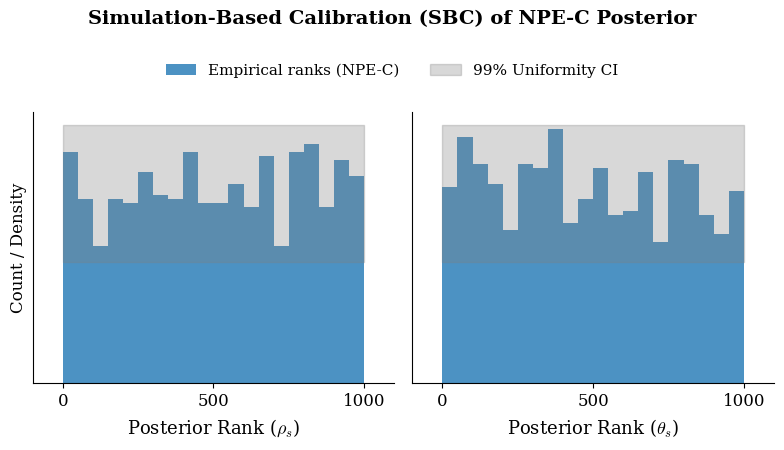

In [98]:
param_names = [r"$\rho_s$", r"$\theta_s$"]
fig, ax = sbc_rank_plot(
    ranks=ranks[:, :2],
    num_posterior_samples=num_posterior_samples,
    plot_type="hist",
    num_bins=20,
    figsize=(8, 4),
    parameter_labels=param_names,
    ranks_labels=["Empirical ranks (NPE-C)"],    # Replaces generic "rank set 1"
    colors=["#1f77b4"]                         # Matches your posterior corner plot
)

for i, a in enumerate(ax):
    a.set_xlabel(f"Posterior Rank ({param_names[i]})", fontsize=13, labelpad=6)
    
    a.spines["top"].set_visible(False)
    a.spines["right"].set_visible(False)

ax[0].set_ylabel("Count / Density", fontsize=12)

handles, labels = ax[0].get_legend_handles_labels()
if ax[0].get_legend() is not None:
    ax[0].get_legend().remove()

updated_labels = [
    "99% Uniformity CI" if "uniform" in lbl.lower() else lbl 
    for lbl in labels
]

fig.legend(
    handles, 
    updated_labels, 
    loc="upper center", 
    bbox_to_anchor=(0.5, 1.02),
    ncol=2, 
    frameon=False, 
    fontsize=11
)

fig.suptitle(
    "Simulation-Based Calibration (SBC) of NPE-C Posterior", 
    fontsize=14, 
    fontweight="bold", 
    y=1.12
)

plt.tight_layout()
plt.savefig('../output/CO_sbc_hist.pdf', format='pdf', bbox_inches='tight')
plt.show()

### TARP

In [92]:
tarp_results = []
np.random.seed(100)
torch.manual_seed(100)
num_posterior_samples = 1000
parameter_labels = [r"for $\rho_s$", r"for $\theta_s$", r"for L"]
ecp, alpha = run_tarp(
    theta_test,
    x_test,
    posterior,
    num_posterior_samples=num_posterior_samples,
    use_batched_sampling=False
)

Sampling 998 times (1000,) posterior samples.: 100%|██████████| 998/998 [00:25<00:00, 38.75it/s]


In [93]:
stats_tarp = check_tarp(
    ecp,
    alpha
)
print(stats_tarp)

tarp_results.append({
    "ecp": ecp,
    "alpha": alpha,
    "stats": stats_tarp
})

(0.0005869365413673222, np.float64(0.9999999999962054))


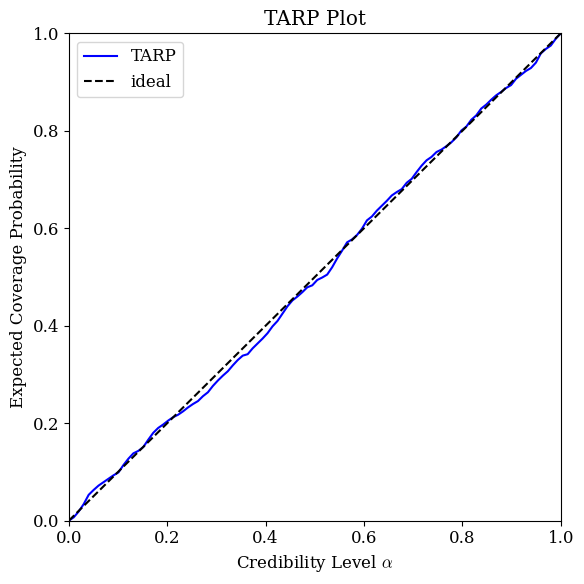

In [94]:
fig, ax = plot_tarp(
    ecp, 
    alpha,
    title="TARP Plot"
)

plt.tight_layout()
plt.show()

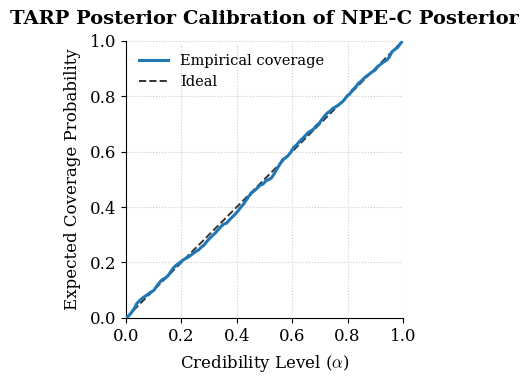

In [104]:
fig, ax = plot_tarp(
    ecp, 
    alpha,
    title=""
)

fig.set_size_inches(4, 4)
lines = ax.get_lines()
if len(lines) >= 2:
    lines[0].set_color("#1f77b4")
    lines[0].set_linewidth(2.2)
    lines[0].set_label("Empirical coverage")
    lines[0].set_zorder(3)
    
    lines[1].set_color("#333333")
    lines[1].set_linestyle("--")
    lines[1].set_linewidth(1.4)
    lines[1].set_label("Ideal")
    lines[1].set_zorder(2)

for collection in ax.collections:
    collection.set_facecolor("#1f77b4")
    collection.set_alpha(0.25)

ax.set_xlabel(r"Credibility Level ($\alpha$)", fontsize=12, labelpad=6)
ax.set_ylabel("Expected Coverage Probability", fontsize=12, labelpad=6)
ax.set_xlim(0.0, 1.0)
ax.set_ylim(0.0, 1.0)
ax.set_aspect("equal", adjustable="box")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(True, linestyle=":", alpha=0.4, color="gray", zorder=0)

# Optional: Subtle diagnostic region labels (standard in calibration literature)
# ax.text(0.28, 0.72, "Underconfident\n(Conservative)", fontsize=9.5, color="#666666", 
#         ha="center", va="center", style="italic")
# ax.text(0.72, 0.28, "Overconfident\n(Biased / Narrow)", fontsize=9.5, color="#666666", 
#         ha="center", va="center", style="italic")

ax.legend(loc="upper left", frameon=False, fontsize=10.5)
ax.set_title("TARP Posterior Calibration of NPE-C Posterior", fontsize=14, fontweight="bold", pad=12)

plt.tight_layout()
plt.savefig('../output/CO_tarp.pdf', format='pdf', bbox_inches='tight')
plt.show()

### Coverage at 95%

In [112]:
def marginal_coverage95(theta_est_post, theta_test_numpy):
    print("\nMarginal 1D Coverage Metrics (95% Interval):")
    print("-" * 40)

    lower_bounds = np.percentile(theta_est_post, 2.5, axis=1)
    upper_bounds = np.percentile(theta_est_post, 97.5, axis=1)
    is_covered = (theta_test_numpy >= lower_bounds) & (theta_test_numpy <= upper_bounds)
    marginal_coverages = np.mean(is_covered, axis=0)

    for d, coverage in enumerate(marginal_coverages):
        print(f"Dimension {d} Coverage: {coverage * 100:.1f}%")
    print("-" * 40)
    
    return marginal_coverages

In [113]:
marginal_coverage95(theta_test_post, theta_numpy)


Marginal 1D Coverage Metrics (95% Interval):
----------------------------------------
Dimension 0 Coverage: 93.6%
Dimension 1 Coverage: 95.1%
Dimension 2 Coverage: 99.9%
----------------------------------------


array([0.93587174, 0.9509018 , 0.998998  ])

### Posterior mean error

In [114]:
def L2_error(theta_est_post, theta_test_numpy):
    post_mean_error = np.full((theta_est_post.shape[0]), np.nan)
    for i in range(theta_est_post.shape[0]):
        post_mean = np.mean(theta_est_post[i, :, :], axis=0)
        error = post_mean - theta_test_numpy[i, :]
        post_mean_error[i] = np.linalg.norm(error)
    return post_mean_error

In [115]:
post_mean_error = L2_error(theta_test_post, theta_numpy)

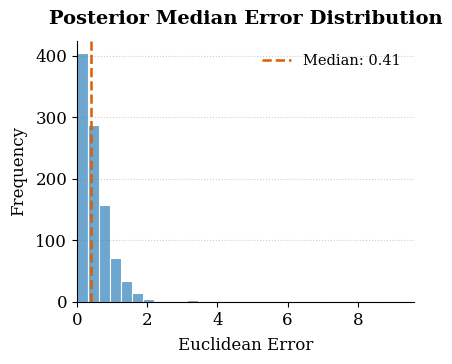

In [126]:
# Flatten array just in case it has shape (N, 1)
errors = np.asarray(post_mean_error).flatten()

median_err = np.median(errors)
mean_err = np.mean(errors)
# q95_err = np.percentile(errors, 95)
x_max = np.percentile(errors, 99.5) * 1.15  # Focus on 99.5% of the data

fig, ax = plt.subplots(figsize=(4.4, 3.8))

sns.histplot(
    errors[errors <= x_max],
    bins=28,
    color="#1f77b4",
    edgecolor="white",
    alpha=0.65,
    kde=False,
    ax=ax
)

ax.axvline(
    median_err, color="#d95f02", linestyle="--", linewidth=1.8,
    label=f"Median: {median_err:.2f}"
)
# ax.axvline(
#     q95_err, color="#333333", linestyle=":", linewidth=1.6,
#     label=f"95th Percentile: {q95_err:.2f}"
# )

ax.set_xlim(0, x_max)
ax.set_xlabel("Euclidean Error", fontsize=12, labelpad=6)
ax.set_ylabel("Frequency", fontsize=12,labelpad=6)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle=":", alpha=0.4, color="gray", zorder=0)

ax.legend(loc="upper right", frameon=False, fontsize=10.5)

ax.set_title("Posterior Median Error Distribution", fontsize=14, fontweight="bold", pad=12)

plt.tight_layout()
plt.savefig('../output/CO_error.pdf', format='pdf', bbox_inches='tight')
plt.show()